# hBN bilayer: the bands of one layer inside the bilayer

**Goal.** The effective scheme computes the GW bands of one layer, with the other layer (the "substrate") entering only
through its screening. To test it we need, from the explicit GW of the bilayer, the GW bands of the top layer *inside
the bilayer*. The bilayer has twice the bands of one layer (one copy per layer, mixed where the two layers interact):
we attribute each bilayer state to the top or to the bottom layer and keep only the bands of the top layer, i.e. half
of the original bands. The final figure compares them with the GW bands of the top layer alone: their difference is
what the embedding has to reproduce.

Steps:
1. the GW bands of the bilayer (input);
2. the states of the top layer alone, on the same k path;
3. how much of each bilayer state belongs to the top layer;
4. the bands of the top layer inside the bilayer;
5. result and export.

Stackings AA' and AB; 3 valence bands and the lowest conduction band per layer (bilayer bands 3-10, layer bands 2-5).
Inputs: `results/gw_bands.json` (DFT and GW bands on $\Gamma$-M-K-$\Gamma$, 181 k points, from GW_Analysis.ipynb) and the
wavefunctions of the pw.x bands runs on the same path (`DFT_analysis/bands-<system>.save`). No new calculation.

## The idea
A bilayer state $\psi_n$ is in general a combination of states of the two layers. The weight of the top-layer state
$\phi_m$ in $\psi_n$ (same k point) is

$$P_{mn} = |\langle \phi_m | \psi_n \rangle|^2 , \qquad 0 \le P_{mn} \le 1 .$$

Three cases:
- $P_{mn} \simeq 1$: the bilayer state is the top-layer state (e.g. AB at K, where the two layers are not equivalent and
  their states do not mix);
- $P_{mn} \simeq 0$: the bilayer state belongs to the other layer;
- $P_{mn} \simeq 0.5$: the top-layer state is shared by two bilayer states, a bonding and an antibonding combination of
  the two layers (AA', whose layers are equivalent, and AB away from K).

**Which layer a bilayer state belongs to** (step 3): for each bilayer state $\psi_n$, its weights on the states of the
top layer and on those of the bottom layer.

**Bands of the top layer** (step 4). Fix a top-layer state $\phi_m$ and scan all the bilayer states at the same k. Keep
the states that carry weight, $P_{mn} \ge 0.05$. If their weights add up to about 1,

$$S_m = \sum_{n\ \mathrm{kept}} P_{mn} \ge 0.9 ,$$

the state $\phi_m$ is contained in them, $\phi_m \simeq \sum_{n\ \mathrm{kept}} \langle\psi_n|\phi_m\rangle\, \psi_n$, and it
is attributable to the bilayer; its energy inside the bilayer is the weighted mean

$$E_m = \frac{1}{S_m} \sum_{n\ \mathrm{kept}} P_{mn}\, E_n .$$

Over *all* the bilayer states the weights always add up to 1 (the bilayer states are a complete set): the condition is
that a few states carry the whole weight. The kept states must also have the occupation of $\phi_m$: a valence state of
the layer is made of occupied bilayer states, a conduction state of empty ones. Otherwise $\phi_m$ is not attributable.

Why the weighted mean. If $\phi_m$ lies in one bilayer state, $E_m$ is the energy of that state. If it is shared by two
states, the sharing comes from the coupling $t$ between the two layers. In a two-level model,
$H = \begin{pmatrix} e_{top} & t \\ t & e_{bot} \end{pmatrix}$, the two eigenstates have energies $E_1, E_2$ and weights
$P_1, P_2$ of $\phi_{top}$, and $P_1 E_1 + P_2 E_2 = \langle\phi_{top}|H|\phi_{top}\rangle = e_{top}$ for any weights: the
mean is the energy of the top-layer state with the coupling switched off (AA': $e_{top} = e_{bot} = e$, weights 1/2,
energies $e \pm t$, mean $e$). This is what the effective scheme describes: it has no coupling between the layers.
In G0W0 the GW states are the DFT states, so the same weights serve for the DFT and for the GW energies.

With the plane-wave expansion $\psi_n(\mathbf r) = \sum_{\mathbf G} c_n(\mathbf G)\, e^{i(\mathbf k+\mathbf G)\cdot\mathbf r}$
(same cell, cutoff and k for all the runs) the overlap is $\langle\phi_m|\psi_n\rangle = \sum_{\mathbf G} c^{*}_m(\mathbf G)\,
c_n(\mathbf G)$. Degenerate states are defined only up to a mixing within their group (e.g. the pairs of AA' at K): the
weights are averaged over each group of degenerate states.

In [1]:
import os, json, datetime
import numpy as np
import xml.etree.ElementTree as ET
from scipy.io import FortranFile
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

Ha = 27.211386245988                          # eV
names = {'AA1': "AA'", 'AB': 'AB'}
with open('results/gw_bands.json') as f:
    gw = json.load(f)
hs = gw['path']['high_symmetry_positions']
x = np.array(gw['systems']['AA1']['kpath'])  # the 181 k points of the pw.x bands runs (same path for all the systems)

def bands_run(system):
    return os.path.join('DFT_analysis', 'bands-%s.save' % system)

def read_xml(save):
    # KS energies (eV, k x bands) and atoms [(name, position in bohr)] of a QE run
    out = ET.parse(os.path.join(save, 'data-file-schema.xml')).getroot().find('output')
    e = np.array([[float(v) for v in k.find('eigenvalues').text.split()] for k in out.find('band_structure').findall('ks_energies')]) * Ha
    atoms = [(a.get('name'), np.array([float(v) for v in a.text.split()])) for a in out.find('atomic_structure/atomic_positions').findall('atom')]
    return e, atoms

def read_wfc(save, ik, nbnd):
    # plane-wave coefficients c_n(G) of the first nbnd states at the k point ik (1-based), from the QE file wfc<ik>.dat
    with FortranFile(os.path.join(save, 'wfc%d.dat' % ik), 'r') as f:
        head = f.read_record('i4,3f8,i4,i4,f8')              # ik, k (cartesian, bohr^-1), ispin, gamma_only, scale factor
        ngw, npw, npol, nb = f.read_ints('i4')
        b = f.read_reals('f8').reshape(3, 3)                   # reciprocal vectors (bohr^-1)
        mill = f.read_ints('i4').reshape(npw, 3)               # Miller indices of the G vectors
        c = np.array([f.read_reals('f8').view(complex) for _ in range(min(nb, nbnd))])
    return {'k': head['f1'][0], 'b': b, 'mill': mill, 'c': c}

gkey = lambda mill: ((mill[:, 0] + 512) * 1024 + mill[:, 1] + 512) * 1024 + mill[:, 2] + 512   # one integer per G vector

def overlap(w1, w2):
    # <phi_m|psi_n> = sum_G c1*_m(G) c2_n(G), with the G vectors of the two runs matched through their Miller indices
    _, i1, i2 = np.intersect1d(gkey(w1['mill']), gkey(w2['mill']), return_indices=True)
    return w1['c'][:, i1].conj() @ w2['c'][:, i2].T

def degenerate_groups(e, tol=1e-3):
    # groups of degenerate bands (within 1 meV); the last group is dropped because it may be incomplete
    groups = [[0]]
    for i in range(1, len(e)):
        if e[i] - e[groups[-1][-1]] < tol: groups[-1].append(i)
        else: groups.append([i])
    return groups[:-1]

def set_path_axis(ax):
    for p in hs: ax.axvline(p, color='gray', lw=0.5)
    ax.set_xticks(hs); ax.set_xticklabels(['$\\Gamma$', 'M', 'K', '$\\Gamma$'], size=12); ax.set_xlim(hs[0], hs[-1])

## 1. GW bands of the bilayer
Bilayer bands 3-10: 3 valence bands and the lowest conduction band of each layer (zero = DFT VBM). Each band of the layer
appears twice. At K the two copies coincide in AA' (equivalent layers) and are slightly split in AB (inequivalent
layers); at M and $\Gamma$ they are split by the interaction of the two layers in both stackings.

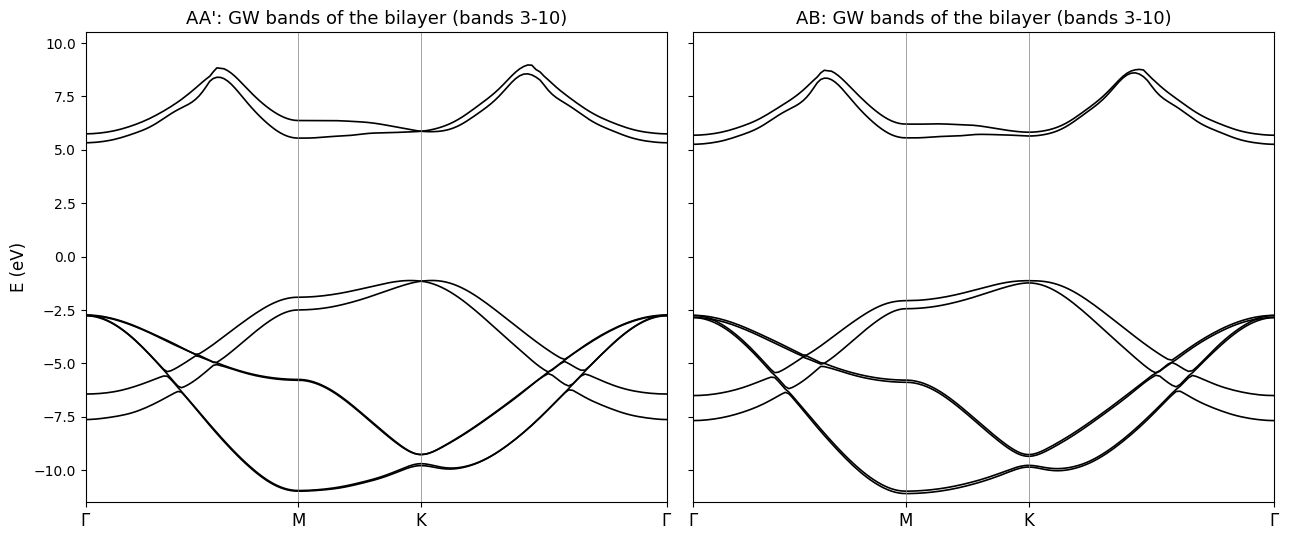

In [2]:
def bilayer_bands(bl, level):
    # bilayer bands 3-14 on the path ('ks' = DFT, 'qp' = GW), one row per DFT band index, eV
    return np.array(gw['systems'][bl]['bands_' + level])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, bl in zip(axes, ['AA1', 'AB']):
    for e in np.sort(bilayer_bands(bl, 'qp'), axis=0)[:8]:
        ax.plot(x, e, 'k', lw=1.2)
    set_path_axis(ax); ax.set_ylim(-11.5, 10.5); ax.set_title('%s: GW bands of the bilayer (bands 3-10)' % names[bl], size=13)
axes[0].set_ylabel('E (eV)', size=12)
plt.tight_layout()

## 2. States of the top layer alone
The top layer is the bottom layer (`ML_bot`, computed alone) moved to its position in the bilayer: translated by
$\boldsymbol\tau$ in AB, rotated by 180$^\circ$ about z ($C_{2z}$) and translated in AA'. Its states are the states of
`ML_bot` moved in the same way. In plane waves:
- AB: $c^{top}_m(\mathbf G) = e^{-i(\mathbf k+\mathbf G)\cdot\boldsymbol\tau}\, c^{bot}_m(\mathbf G)$;
- AA': $c^{top}_m(G_x, G_y, G_z) = e^{-i(\mathbf k+\mathbf G)\cdot\boldsymbol\tau}\, c^{bot\,*}_m(G_x, G_y, -G_z)$ (the
  rotation takes $\mathbf k$ to $-\mathbf k$; time reversal, i.e. the complex conjugation, brings it back to $\mathbf k$).

So the top-layer states along the path come from the bands run of `ML_bot`, with no new calculation. Check: on the
k = 18 grid they coincide with the states of the runs of the top layer alone (`ML_top_AA1`, `ML_top_AB`).

In [3]:
C2z = np.diag([-1., -1., 1.])
e_bot, atoms_bot = read_xml(bands_run('ML_bot'))
r_bot = dict(atoms_bot)

def top_state(w, bl):
    # states of the top layer of the bilayer bl, built from the states w of ML_bot
    r_top = {name: r for name, r in read_xml(bands_run(bl))[1] if r[2] > 0}       # atoms of the top layer (z > 0)
    if bl == 'AB':                                     # translation
        tau, c = r_top['B'] - r_bot['B'], w['c']
    else:                                              # rotation C2z + translation, with time reversal
        tau = r_top['B'] - C2z @ r_bot['B']
        index = {g: i for i, g in enumerate(gkey(w['mill']))}
        c = w['c'][:, [index[g] for g in gkey(w['mill'] * np.array([1, 1, -1]))]].conj()
    kG = w['k'] + w['mill'] @ w['b']
    return dict(w, c=c * np.exp(-1j * kG @ tau)[None, :])

# check at K (k = 18 grid): sum over each degenerate group of |<built|computed>|^2 must equal the size of the group
nscf = lambda s: os.path.join('DFT_analysis', 'kpoints_18-nbnds_250-%s.save' % s)
for bl in ['AA1', 'AB']:
    e18 = read_xml(nscf('ML_bot'))[0][36, :20]
    O = overlap(read_wfc(nscf('ML_top_' + bl), 37, 20), top_state(read_wfc(nscf('ML_bot'), 37, 20), bl))
    err = max(abs((abs(O[np.ix_(g, g)]) ** 2).sum() - len(g)) for g in degenerate_groups(e18))
    print('%s: top-layer states built from ML_bot vs the run of the top layer alone: max deviation %.0e' % (names[bl], err))

AA': top-layer states built from ML_bot vs the run of the top layer alone: max deviation 4e-06
AB: top-layer states built from ML_bot vs the run of the top layer alone: max deviation 3e-06


## 3. How much of each bilayer state belongs to the top layer
At each k point of the path: weights $P_{mn}$ of the top-layer bands $m$ = 1-8 on the bilayer bands $n$ = 1-20, and the
same for the bottom layer. The weight of the bilayer state $n$ on a layer is $L_n = \sum_m P_{mn}$; the figure colours
each bilayer state by its fraction on the top layer, $L^{top}_n / (L^{top}_n + L^{bot}_n)$: red = top layer, blue =
bottom layer, purple = shared by the two layers.

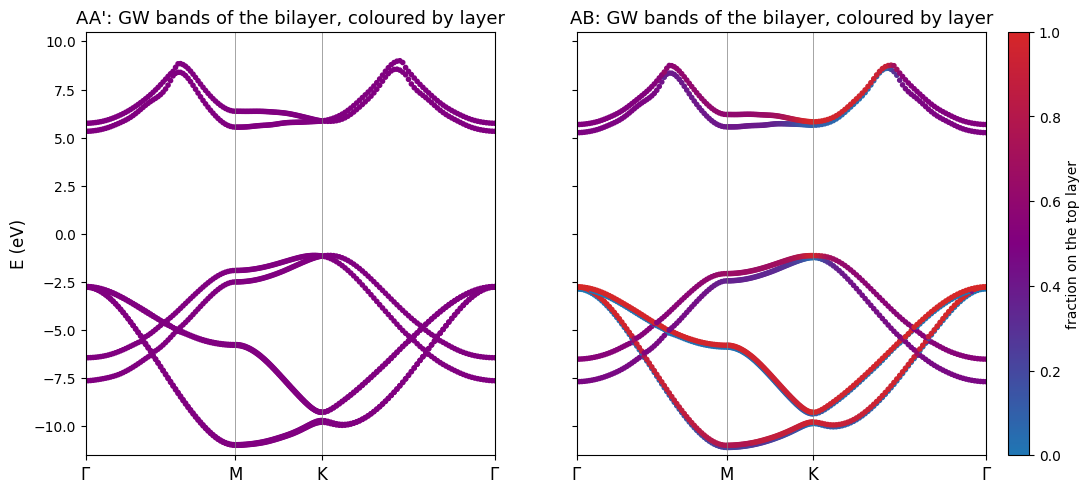

In [4]:
def weights(bl):
    # P[layer][k, m, n]: weights of the layer bands m = 1-8 on the bilayer bands n = 1-20, averaged over degenerate groups
    e_bl = read_xml(bands_run(bl))[0]
    P = {'top': np.zeros((len(x), 8, 20)), 'bot': np.zeros((len(x), 8, 20))}
    for ik in range(len(x)):
        g_bl, g_ml = degenerate_groups(e_bl[ik]), degenerate_groups(e_bot[ik])
        w_bl = read_wfc(bands_run(bl), ik + 1, g_bl[-1][-1] + 1)
        w_bot = read_wfc(bands_run('ML_bot'), ik + 1, g_ml[-1][-1] + 1)
        for layer, w in [('bot', w_bot), ('top', top_state(w_bot, bl))]:
            p = abs(overlap(w, w_bl)) ** 2
            for gm in g_ml:
                for gn in g_bl:
                    p[np.ix_(gm, gn)] = p[np.ix_(gm, gn)].mean()
            P[layer][ik] = p[:8, :20]
    return P

P = {bl: weights(bl) for bl in ['AA1', 'AB']}
top_fraction = {bl: P[bl]['top'].sum(axis=1) / (P[bl]['top'].sum(axis=1) + P[bl]['bot'].sum(axis=1)) for bl in P}   # k x n

cmap = LinearSegmentedColormap.from_list('layers', ['tab:blue', 'purple', 'tab:red'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, bl in zip(axes, ['AA1', 'AB']):
    E = bilayer_bands(bl, 'qp')
    for n in range(3, 11):
        sc = ax.scatter(x, E[n - 3], c=top_fraction[bl][:, n - 1], cmap=cmap, vmin=0, vmax=1, s=9)
    set_path_axis(ax); ax.set_ylim(-11.5, 10.5); ax.set_title('%s: GW bands of the bilayer, coloured by layer' % names[bl], size=13)
axes[0].set_ylabel('E (eV)', size=12)
plt.colorbar(sc, ax=axes, label='fraction on the top layer', pad=0.02)

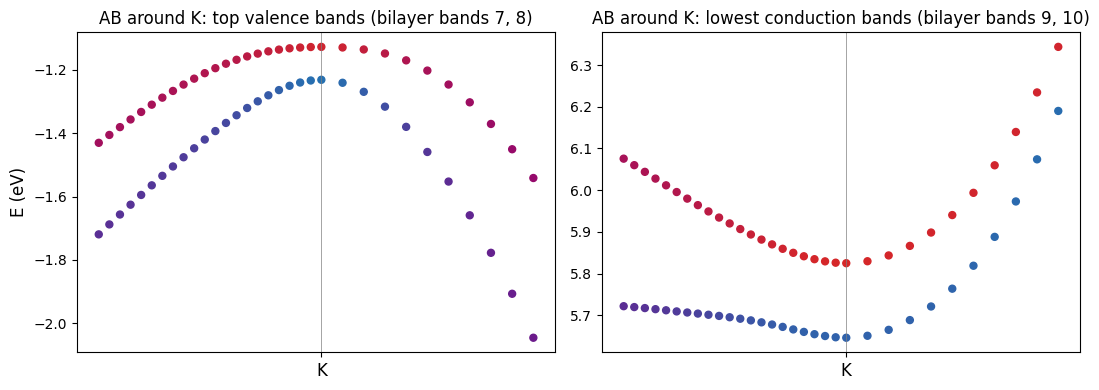

In [5]:
# zoom around K for AB: there the two copies of each band are 0.1-0.2 eV apart, each on one layer
win = (x > hs[2] - 0.12) & (x < hs[2] + 0.12)
E = bilayer_bands('AB', 'qp')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, ns, what in [(axes[0], [7, 8], 'top valence bands'), (axes[1], [9, 10], 'lowest conduction bands')]:
    for n in ns:
        ax.scatter(x[win], E[n - 3][win], c=top_fraction['AB'][win, n - 1], cmap=cmap, vmin=0, vmax=1, s=25)
    ax.axvline(hs[2], color='gray', lw=0.5); ax.set_xticks([hs[2]]); ax.set_xticklabels(['K'], size=12)
    ax.set_title('AB around K: %s (bilayer bands %d, %d)' % (what, ns[0], ns[1]), size=12)
axes[0].set_ylabel('E (eV)', size=12)
plt.tight_layout()

- **AA'**: every bilayer state is purple, i.e. half on the top layer and half on the bottom one, at every k. The two
  layers are equivalent, so each bilayer state is a bonding or antibonding combination of the two copies of a band:
  each band of the top layer is shared by a pair of bilayer bands.
- **AB**: the $\sigma$ bands (lower valence bands, weakly coupled) lie each on one layer (red or blue) along most of the
  path. The $\pi$ valence and $\pi^*$ conduction bands are shared (purple) around M, but separate around K, where the
  two copies are 0.1-0.2 eV apart: one is on the top layer, the other on the bottom one (zoom).

Where a bilayer state lies on one layer, the top-layer band simply follows the red state; where the states are shared,
it lies in the middle of the pair (next step).

## 4. Bands of the top layer inside the bilayer
For each top-layer band $m$ = 2-5 and each k, as described in "The idea": the bilayer states (bands 1-20) with
$P_{mn} \ge 0.05$, the sum $S_m$ of their weights and the energy $E_m$ from their GW (and DFT) energies; attributable if
$S_m \ge 0.9$ and all the kept states have the occupation of $m$. The valence states and the $\pi^*$ conduction states
are always attributable, to one bilayer state (e.g. AB at K) or to a pair (where the two layers are coupled). Around
$\Gamma$ the lowest conduction band of the layer is a nearly-free-electron (NFE) state, which extends into the vacuum
and over the other layer: its weight is either spread over many bilayer states ($S_m < 0.9$) or reaches 0.9 only through
the deep N-2s states of the bilayer (about 20%), i.e. through occupied states. There it is not attributable (dotted:
mean over its conduction states only).

The figure shows the 8 bilayer bands (coloured as above) and the 4 bands of the top layer extracted from them.

AA': attributable k points (of 181) for the top-layer bands 2, 3, 4, 5: [181 181 181 111]
AB : attributable k points (of 181) for the top-layer bands 2, 3, 4, 5: [181 181 181 110]


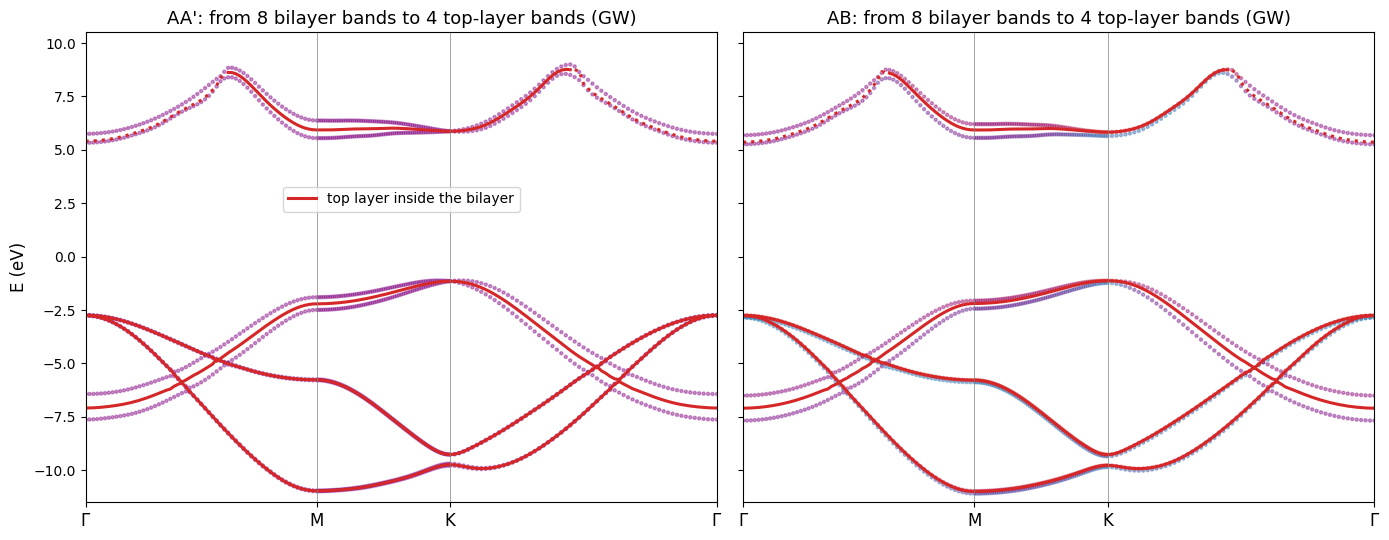

In [6]:
def top_layer_bands(bl, level, pmin=0.05):
    # E_m (rows m = 2-5) of the top layer inside the bilayer bl, level 'ks' (DFT) or 'qp' (GW); S_m = sum of the kept
    # weights; attributable = S_m >= 0.9 and all the kept states with the occupation of m
    E = bilayer_bands(bl, level)                                   # bands 3-14
    Em, Sm = np.full((4, len(x)), np.nan), np.zeros((4, len(x)))
    ok = np.zeros((4, len(x)), dtype=bool)
    for i, m in enumerate(range(2, 6)):
        for ik in range(len(x)):
            p = P[bl]['top'][ik, m - 1]                            # weights of phi_m on the bilayer bands 1-20
            kept = np.where(p >= pmin)[0] + 1                      # bilayer states that carry weight
            same = (kept <= 8) if m <= 4 else (kept >= 9)          # occupation of m (the bilayer has 8 occupied bands)
            Sm[i, ik] = p[kept - 1].sum()
            ok[i, ik] = Sm[i, ik] >= 0.9 and same.all()
            n = kept[same]
            if len(n):
                assert n.min() >= 3 and n.max() <= 14              # the kept states have GW energies (bands 3-14)
                Em[i, ik] = (p[n - 1] * E[n - 3, ik]).sum() / p[n - 1].sum()
    return Em, Sm, ok

top_in, kept_weight, attributable = {}, {}, {}
for bl in ['AA1', 'AB']:
    top_in[bl] = {'ks': top_layer_bands(bl, 'ks')[0]}
    top_in[bl]['qp'], kept_weight[bl], attributable[bl] = top_layer_bands(bl, 'qp')
    print('%-3s: attributable k points (of %d) for the top-layer bands 2, 3, 4, 5: %s' % (names[bl], len(x), attributable[bl].sum(axis=1)))

def plot_top(ax, Em, ok, **kw):
    # extracted bands: solid where attributable, dotted elsewhere
    for i in range(4):
        ax.plot(x, np.where(ok[i], Em[i], np.nan), '-', label=kw.get('label') if i == 0 else None, color=kw['color'], lw=kw.get('lw', 1.8))
        ax.plot(x, np.where(ok[i], np.nan, Em[i]), ':', color=kw['color'], lw=kw.get('lw', 1.8))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, bl in zip(axes, ['AA1', 'AB']):
    E = bilayer_bands(bl, 'qp')
    for n in range(3, 11):
        ax.scatter(x, E[n - 3], c=top_fraction[bl][:, n - 1], cmap=cmap, vmin=0, vmax=1, s=5, alpha=0.4)
    plot_top(ax, top_in[bl]['qp'], attributable[bl], color='tab:red', lw=2.2, label='top layer inside the bilayer')
    set_path_axis(ax); ax.set_ylim(-11.5, 10.5); ax.set_title('%s: from 8 bilayer bands to 4 top-layer bands (GW)' % names[bl], size=13)
axes[0].set_ylabel('E (eV)', size=12); axes[0].legend(loc='center', bbox_to_anchor=(0.5, 0.645))
plt.tight_layout()

## 5. Result: GW bands of the top layer, inside the bilayer and alone
Red: bands of the top layer extracted from the bilayer (step 4). Blue: GW bands of the top layer alone (`ML_bot`, the
same as the top layer by symmetry). Zero = DFT VBM of each system: in DFT the top layer inside the bilayer and alone are
almost identical (table below), so this is a common reference.

energies (eV)                 DFT alone  DFT inside |  GW alone  GW inside | GW inside - alone
AA'  Gamma top valence         -1.372    -1.339   |   -2.966    -2.750  |  +0.216
AA'  Gamma lowest conduction    4.714     4.948   |    5.346     5.406  |  +0.059  (not attributable)
AA'  M     top valence         -0.905    -0.904   |   -2.397    -2.209  |  +0.188
AA'  M     lowest conduction    4.834     4.854   |    6.133     5.931  |  -0.202
AA'  K     top valence         -0.000    -0.001   |   -1.320    -1.150  |  +0.170
AA'  K     lowest conduction    4.713     4.764   |    6.018     5.869  |  -0.149
AB   Gamma top valence         -1.372    -1.356   |   -2.966    -2.754  |  +0.212
AB   Gamma lowest conduction    4.714     4.907   |    5.346     5.360  |  +0.014  (not attributable)
AB   M     top valence         -0.905    -0.916   |   -2.397    -2.195  |  +0.202
AB   M     lowest conduction    4.834     4.852   |    6.133     5.929  |  -0.204
AB   K     top valence         -0.000    -0.0

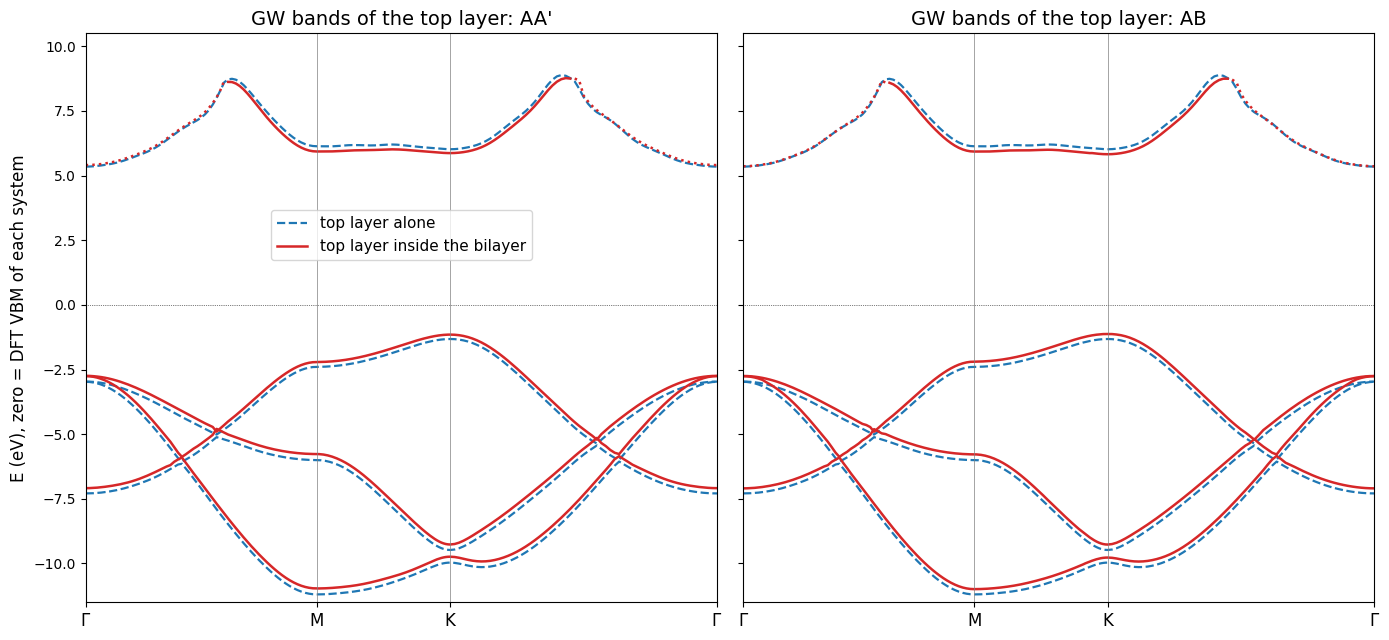

In [7]:
top_alone = {lev: np.array(gw['systems']['ML_bot']['bands_' + lev])[:4] for lev in ['ks', 'qp']}   # layer bands 2-5

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, bl in zip(axes, ['AA1', 'AB']):
    for i in range(4):
        ax.plot(x, top_alone['qp'][i], '--', color='tab:blue', lw=1.6, label='top layer alone' if i == 0 else None)
    plot_top(ax, top_in[bl]['qp'], attributable[bl], color='tab:red', label='top layer inside the bilayer')
    ax.axhline(0, color='k', lw=0.5, ls=':')
    set_path_axis(ax); ax.set_ylim(-11.5, 10.5); ax.set_title('GW bands of the top layer: %s' % names[bl], size=14)
axes[0].set_ylabel('E (eV), zero = DFT VBM of each system', size=12)
axes[0].legend(loc='center', bbox_to_anchor=(0.5, 0.645), fontsize=11)
plt.tight_layout()

# top valence band (m = 4) and lowest conduction band (m = 5) at Gamma, M, K
print('energies (eV)                 DFT alone  DFT inside |  GW alone  GW inside | GW inside - alone')
for bl in ['AA1', 'AB']:
    for lab, p in zip(['Gamma', 'M', 'K'], hs[:3]):
        ik = int(np.argmin(abs(x - p)))
        for i, band in [(2, 'top valence'), (3, 'lowest conduction')]:
            note = '' if attributable[bl][i, ik] else '  (not attributable)'
            print('%-4s %-5s %-17s %8.3f  %8.3f   | %8.3f  %8.3f  |  %+.3f%s' % (names[bl], lab, band, top_alone['ks'][i, ik],
                  top_in[bl]['ks'][i, ik], top_alone['qp'][i, ik], top_in[bl]['qp'][i, ik], top_in[bl]['qp'][i, ik] - top_alone['qp'][i, ik], note))
iK = int(np.argmin(abs(x - hs[2])))
print('\nGW gap of the top layer at K: alone %.3f eV; inside AA\' %.3f eV; inside AB %.3f eV' % (
      top_alone['qp'][3, iK] - top_alone['qp'][2, iK], *[top_in[bl]['qp'][3, iK] - top_in[bl]['qp'][2, iK] for bl in ['AA1', 'AB']]))

- The two band structures have the same shape: the second layer does not deform the bands of the top layer, it
  shifts them.
- Shift (inside the bilayer - alone) on 90% of the path: valence bands +0.17 to +0.24 eV, lowest conduction band
  ($\pi^*$) -0.15 to -0.22 eV; isolated points (0.11-0.32 eV in the valence) lie near band crossings, where the GW
  interpolation between the grid points is the least accurate (GW_Analysis). GW gap of the top layer at K: 7.34 eV
  alone, 7.02 eV inside AA', 6.95 eV inside AB (at K the top-layer states are bilayer states: these are their QP
  energies).
- In DFT the top layer inside the bilayer and alone are almost identical (within 0.05 eV for the valence bands,
  0.01-0.08 eV for the $\pi^*$ band), so the shift appears with GW: it comes from the screening of the second layer.
  This is what the embedding has to reproduce, starting from the blue bands (layer alone) and adding the screening of
  the other layer.
- AA' and AB differ by at most 0.05 eV: the stacking matters little (the embedding gives almost the same result for
  both).
- Dotted: the lowest conduction band around $\Gamma$ (NFE states, not attributable to one layer), excluded from the
  comparison.

## Export (`results/layer_projection.json`)
Bands of the top layer (2-5) on the path, alone and inside each bilayer, DFT and GW, with the sum $S_m$ of the kept weights
and the attributable flag; fraction on the top layer of the bilayer bands 3-10 (for the coloured figure). Read by Results.ipynb.

In [8]:
def to_list(a, nd=4):
    return np.round(np.asarray(a, dtype=float), nd).tolist()

def write_json(obj, path):
    # indented JSON with each list of numbers on a single line
    def enc(o, ind):
        pad = ' ' * ind
        if isinstance(o, dict):
            return '{\n' + ',\n'.join('%s  %s: %s' % (pad, json.dumps(k), enc(v, ind + 2)) for k, v in o.items()) + '\n' + pad + '}'
        if isinstance(o, list) and any(isinstance(v, (dict, list)) for v in o):
            return '[\n' + ',\n'.join(pad + '  ' + enc(v, ind + 2) for v in o) + '\n' + pad + ']'
        return json.dumps(o)
    with open(path, 'w') as fl: fl.write(enc(obj, 0) + '\n')
    print('written', path, '(%.1f kB)' % (os.path.getsize(path) / 1e3))

proj = {'metadata': {
    'description': 'Bands of the top layer inside the bilayer, extracted from the explicit bilayer bands with the weights '
                   'P_mn = |<phi_m|psi_n>|^2 of the top-layer states phi_m (ML_bot moved to the top position by symmetry) '
                   'on the bilayer states psi_n (bands 1-20); kept states: P_mn >= 0.05, S_m = sum of their weights; '
                   'E_m = sum_kept P_mn E_n / S_m; attributable if S_m >= 0.9 and all the kept states have the occupation '
                   'of m (not attributable: NFE states around Gamma; there E_m is the mean over the kept conduction states); '
                   'weights averaged over degenerate groups. Compared with the bands of the top layer alone (= ML_bot). '
                   'Bilayer and layer energies '
                   'from gw_bands.json (KS = PBE bands run, QP = G0W0 PPA interpolated by ypp).',
    'units': 'path coordinate in 2pi/a; energies in eV, zero at the KS VBM of each system (k = 18 grid)',
    'source_notebook': 'hBN_bilayer/Projection_Analysis.ipynb',
    'source_runs': 'DFT_analysis/bands-<system>.save (wavefunctions); results/gw_bands.json (energies)',
    'code': 'Quantum ESPRESSO 7.0 wavefunctions, python (numpy, scipy)', 'date': str(datetime.date.today())},
    'path': {'labels': ['Gamma', 'M', 'K', 'Gamma'], 'high_symmetry_positions': hs, 'kpath': to_list(x, 6)},
    'top_layer_alone': {'bands': [2, 5], 'dft': to_list(top_alone['ks']), 'gw': to_list(top_alone['qp'])},
    'systems': {bl: {'top_layer_inside': {'bands': [2, 5], 'dft': to_list(top_in[bl]['ks']), 'gw': to_list(top_in[bl]['qp']),
                                          'kept_weight_S': to_list(kept_weight[bl], 3),
                                          'attributable': attributable[bl].astype(int).tolist()},
                     'bilayer': {'bands': [3, 10], 'gw': to_list(bilayer_bands(bl, 'qp')[:8]),
                                 'top_fraction': to_list(top_fraction[bl][:, 2:10].T, 3)}} for bl in ['AA1', 'AB']}}
write_json(proj, 'results/layer_projection.json')

written results/layer_projection.json (98.6 kB)
